# TRIPS: Análisis Exploratorio de Datos y Matriz Tractora de Asignación Relacional

El archivo `trips.txt` constituye el núcleo operacional dinámico de la EMT de Madrid, actuando como la matriz tractora de asignación relacional que unifica la infraestructura fija del sistema con la programación de servicios. En la arquitectura de este proyecto de Machine Learning, el análisis de este conjunto de datos representa el eslabón crítico de linaje: es el encargado de generar la variable raíz `trip_id` (Identificador Único de Viaje), clave primaria absoluta de la que dependerán de forma jerárquica y cronológica las tablas transaccionales de horarios de paso en marquesinas e intervalos de regularidad de la red.

### Objetivos del Diagnóstico:
1. **Auditoría de Claves y Linaje de Datos:** Validar la integridad referencial y la unicidad del indexador `trip_id`, asegurando la consistencia relacional de sus claves foráneas frente a los catálogos ya saneados de rutas (`route_id`), calendarios (`service_id`) y trazados geométricos (`shape_id`).

2. **Parametrización de Bloques y Flotas (`block_id`):** Examinar la distribución de turnos de trabajo y asignación de vehículos para modelar el comportamiento del carrusel operativo de autobuses, proxy indispensable para asimilar la fatiga de las líneas.

3. **Discriminación Vectorial de Sentido (`direction_id`):** Validar la consistencia binaria de las orientaciones de marcha (Ida frente a Vuelta) para mitigar ruidos analíticos en el cálculo geográfico de asimetrías de tráfico en Madrid.

4. **Optimización del Esquema Físico:** Reestructurar el linaje en memoria de la matriz mediante tipos estructurados ligeros de PyArrow (`string` e `int8`), reduciendo la huella de RAM y acelerando los cruces relacionales del pipeline.

Se inicia el flujo de ingeniería de datos ejecutando una inspección estructural preliminar para auditar la dimensionalidad, volumetría y el tipado de los vectores de entrada del DataFrame `trips`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configuración global de visualización de tablas en entorno interactivo
pd.set_option('display.max_columns', None)

print("====== INICIANDO CARGA OPTIMIZADA DE VIAJES OPERATIVOS (PYARROW SCHEMA) ======\n")

# 1. Definición del esquema físico estricto mediante tipos binarios ligeros de PyArrow
trips_dtypes = {
    "route_id": "string[pyarrow]",
    "service_id": "string[pyarrow]",
    "trip_id": "string[pyarrow]",
    "trip_headsign": "string[pyarrow]",
    "direction_id": "int8[pyarrow]",
    "block_id": "string[pyarrow]",
    "shape_id": "string[pyarrow]"
}

# 2. Carga del núcleo operacional dinámico en bruto aplicando el mapa de tipos controlado
trips = pd.read_csv('../data/raw/gtfs/trips.txt', encoding='utf-8', dtype=trips_dtypes)

# 3. Saneamiento preventivo de espacios en identificadores relacionales sin alterar caracteres alfabéticos
columnas_id = ['route_id', 'service_id', 'trip_id', 'block_id', 'shape_id']
for col in columnas_id:
    if col in trips.columns:
        trips[col] = trips[col].str.strip().astype("string[pyarrow]")

print("====== ESTRUCTURA OPERATIVA INICIAL DE TRIPS (METADATOS) ======\n")
print(trips.info())

print("\nMuestra forense preliminar de registros originales (Catálogo de Viajes):")
display(trips.head(5))

====== INICIANDO CARGA OPTIMIZADA DE VIAJES OPERATIVOS (PYARROW SCHEMA) ======

====== ESTRUCTURA OPERATIVA INICIAL DE TRIPS (METADATOS) ======

<class 'pandas.DataFrame'>
RangeIndex: 86871 entries, 0 to 86870
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype        
---  ------         --------------  -----        
 0   route_id       86871 non-null  string       
 1   service_id     86871 non-null  string       
 2   trip_id        86871 non-null  string       
 3   trip_headsign  86871 non-null  string       
 4   direction_id   86871 non-null  int8[pyarrow]
 5   block_id       86871 non-null  string       
 6   shape_id       86871 non-null  string       
dtypes: int8[pyarrow](1), string(6)
memory usage: 7.4 MB
None

Muestra forense preliminar de registros originales (Catálogo de Viajes):


,route_id,service_id,trip_id,trip_headsign,direction_id,block_id,shape_id
0,001,FE,FE0010011,Prosperidad,0,FE001_001,001_A
1,001,FE,FE0010012,Cristo Rey,1,FE001_001,001_B
2,001,FE,FE0010013,Prosperidad,0,FE001_001,001_A
3,001,FE,FE0010014,Cristo Rey,1,FE001_001,001_B
4,001,FE,FE0010015,Prosperidad,0,FE001_001,001_A


### Diagnóstico de Dimensionalidad y Estrategia de Preservación de Datos

La inspección estructural preliminar a través de la salida del método `.info()` confirma el salto de escala hacia la fase operativa del proyecto, revelando una matriz de asignación masiva compuesta estrictamente por **86.871 registros únicos y 7 columnas vectoriales**. A diferencia de los componentes de infraestructura estática analizados previamente, `trips.txt` parametriza la totalidad de las expediciones individuales programadas por la EMT de Madrid para cubrir la demanda de la ciudad, exhibiendo una completitud inicial perfecta con un índice de registros nulos igual a cero (`86871 non-null` en todas las variables). Para maximizar la eficiencia computacional en el pipeline, el esquema se consolida desde la carga en disco bajo los tipos de datos optimizados de PyArrow (`string` e `int8` para el indicador binario de sentido), reduciendo drásticamente la huella de memoria RAM.

**Criterio Técnico de Negocio e Impacto en el Linaje:**
Dada la envergadura relacional de este archivo, que actúa como el núcleo conector de la base de datos, se establece una estrategia de conservación absoluta del 100% de sus variables nativas. El conjunto de datos aloja la clave primaria fundamental `trip_id`, de la cual colgarán de forma jerárquica las tablas transaccionales de horarios de paso en marquesinas, y la clave foránea `block_id`, indispensable para modelar la rotación física de los autobuses. Reducir o submuestrear esta matriz comprometería la integridad referencial del pipeline de Machine Learning, destruyendo la varianza de la oferta de transporte. Mantener intactas las 86.871 filas es obligatorio para que los modelos asimilen la totalidad de los viajes comerciales y sus correlaciones de frecuencia antes de la fase de entrenamiento predictivo.

### 📘 Diccionario de datos

Este notebook utiliza el diccionario de datos definido para el conjunto `trips`.  

El documento completo se encuentra en:

👉 [`../docs/06_trips_Dict.md`](../docs/06_trips_Dict.md)

| Columna | Tipo de Dato (Pandas) | Descripción de Negocio | Rol en el Modelo / Importancia |
| :--- | :--- | :--- | :--- |
| **`route_id`** | `String` a `string[pyarrow]` | Clave foránea alfanumérica que vincula el viaje con su línea comercial correspondiente en el catálogo `routes`. | **Clave Foránea**. Descriptor de línea; clave para heredar el régimen horario y el tipo de ruta (regular, lanzadera, búho). |
| **`service_id`** | `String` a `string[pyarrow]` | Clave foránea alfabética que asocia el viaje con un patrón semanal de operación específico en las tablas `calendar` y `calendar_dates`. | **Clave Foránea**. Descriptor estacional; determina si el viaje responde a un perfil de tráfico laborable, de sábado o festivo. |
| **`trip_id`** | `String` a `string[pyarrow]` | Identificador unívoco absoluto generado por la EMT de Madrid para parametrizar una expedición o viaje individual en una franja horaria. | **Clave Primaria**. El indexador dinámico raíz del proyecto; enlaza relacionalmente con la malla horaria (`stop_times`) y las frecuencias (`frequencies`). |
| **`trip_headsign`** | `String` a `string[pyarrow]` | Texto descriptivo oficial expuesto en los letreros frontales del autobús que indica la terminal de destino del viaje (e.g., cabecera o vuelta). | **Metadato Cualitativo**. Variable de apoyo; útil para la auditoría de nombres e inspecciones de las cabeceras de la flota. |
| **`direction_id`** | `Int64` a `int8[pyarrow]` | Código binario estandarizado por el GTFS que discrimina el sentido de marcha de la expedición (`0`: Trayecto de Ida, `1`: Trayecto de Vuelta). | **Indicador de Sentido**. Variable categórica predictora; permite al modelo aislar las asimetrías de congestión según la dirección del flujo. |
| **`block_id`** | `String` a `string[pyarrow]` | Identificador del bloque o turno de trabajo continuo asignado a un vehículo físico de la flota para encadenar múltiples viajes seguidos. | **Descriptor de Rotación**. Variable predictora de arrastre; proxy para el seguimiento de la asignación del vehículo en cascada. |
| **`shape_id`** | `String` a `string[pyarrow]` | Clave foránea alfanumérica que enlaza el viaje con su trazado continuo de coordenadas geográficas exactas en la tabla `shapes`. | **Clave Foránea**. Descriptor espacial; hereda los mapas vectoriales del recorrido circulatorio. |
| **`volumen_viajes_bloque`** | `Nueva` a `int16[pyarrow]` | Variable sintética continua generada mediante agregación que contabiliza el total de expediciones consecutivas asignadas a un mismo turno físico (`block_id`). | **Predictor de Fatiga Avanzado**. Variable de ingeniería de características; proxy crítico para modelar el arrastre de retrasos en cadena. |

### Control de Duplicados e Integridad de Claves Primarias

Antes de proceder con el análisis de los descriptores de rotación y sentido de la red, es indispensable auditar la matriz operativa para certificar la ausencia de redundancias estructurales o conflictos de unicidad en sus identificadores. Al operar `trips.txt` como la matriz tractora de asignación relacional de la EMT de Madrid, se implementa un control de calidad bidimensional estricto:

1. **Redundancia Absoluta (Filas Idénticas):** Evaluación de registros completamente duplicados en todas sus columnas vectoriales, anomalía habitualmente provocada por fallos en los sistemas de persistencia o en la exportación del paquete original de datos. Su depuración se efectúa mediante filtrado directo.

2. **Colisiones de Clave Primaria (`trip_id`):** Diagnóstico forense sobre la unicidad del identificador de viaje. Se buscan anomalías donde una misma clave de expedición registre dos configuraciones operativas distintas. Desde la perspectiva analítica y de negocio, este escenario constituye una corrupción crítica del linaje: rompería el determinismo relacional del pipeline, provocando que los registros de horarios planificados en las paradas se dupliquen o queden huérfanos, invalidando por completo las predicciones de puntualidad del modelo.

El objetivo de este bloque es cuantificar la presencia de ambos fenómenos para validar la salud estructural del catálogo operativo antes de transferir las variables hacia las fases de validación y limpieza de producción.

In [3]:
print("====== REPORTE DE CONTROL DE DUPLICADOS E INTEGRIDAD (TRIPS) ======\n")

# 1. Cuantificación de redundancias absolutas y colisiones en la clave primaria
duplicados_totales = trips.duplicated().sum()
duplicados_clave = trips['trip_id'].duplicated().sum()

print(f"-> Registros 100% idénticos en bruto detectados: {duplicados_totales}")
print(f"-> Registros con colisión crítica de identificador 'trip_id': {duplicados_clave}")

# 2. Cláusulas de control y toma de decisiones operativas de backend
if duplicados_totales > 0:
    print("\nMuestra forense de filas de viajes idénticas repetidas por error:")
    df_duplicados_completos = trips[trips.duplicated(keep=False)]
    display(df_duplicados_completos.sort_values(by=['trip_id']))
    print("\n[RESOLUCIÓN BACKEND]: Aplicación defensiva de '.drop_duplicates()' en el flujo de producción.")

if duplicados_clave > 0:
    print("\n¡ALERTA CRÍTICA! Se han identificado conflictos graves en la clave primaria:")
    df_duplicados_clave = trips[trips.duplicated(subset=['trip_id'], keep=False)]
    display(df_duplicados_clave.sort_values(by=['trip_id']))
    print("\n[RESOLUCIÓN BACKEND]: Las colisiones de ID de viaje corrompen la base de datos relacional. "
          "Estos registros se desviarán para su aislamiento hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: Cada 'trip_id' parametriza una expedición única y libre de colisiones relacionales.")

====== REPORTE DE CONTROL DE DUPLICADOS E INTEGRIDAD (TRIPS) ======

-> Registros 100% idénticos en bruto detectados: 0
-> Registros con colisión crítica de identificador 'trip_id': 0

Todo limpio: Cada 'trip_id' parametriza una expedición única y libre de colisiones relacionales.


### Diagnóstico de Completitud y Gestión de Valores Ausentes

Una vez validada la integridad referencial y la unicidad de las claves primarias operativas, se procede a ejecutar un diagnóstico sistemático sobre la presencia de registros nulos o valores faltantes (`NaN / None`) desglosados por columna. El objetivo es evaluar la salud interna de la matriz de asignación antes de iniciar la caracterización estadística de las expediciones de la EMT de Madrid.

Desde la perspectiva del modelado predictivo, el control de completitud en `trips.txt` es de severidad absoluta. Al operar esta tabla como el engranaje central del sistema relacional dinámico, cualquier ausencia de información en variables raíz —como las claves de línea (`route_id`), calendarios (`service_id`), identificadores de viaje (`trip_id`) o trazados geométricos (`shape_id`)— constituye una anomalía estructural incorregible. Un nulo en estos campos provocaría que los registros horarios de paso en las marquesinas quedaran huérfanos, rompiendo la coherencia del pipeline de producción.

In [4]:
print("====== REPORTE DE CONTROL DE VALORES AUSENTES (TRIPS) ======\n")

# 1. Cuantificación de valores nulos por columna sobre la matriz de viajes
nulos_por_columna = trips.isna().sum()
print("Conteo de valores nulos por variable operativa:")
print(nulos_por_columna)

# 2. Evaluación de registros incompletos para la toma de acciones correctivas
total_nulos_dataframe = trips.isna().any(axis=1).sum()

if total_nulos_dataframe > 0:
    print(f"\n¡Atención! Se han detectado {total_nulos_dataframe} registros incompletos en la matriz:")
    df_nulos = trips[trips.isna().any(axis=1)]
    display(df_nulos.head(10))
    print("\n[RESOLUCIÓN BACKEND]: Las expediciones incompletas quiebran el linaje de datos relacional. "
          "Se programará su desvío automático hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: El 100% de la matriz operativa de viajes está completa (cero registros nulos).")

====== REPORTE DE CONTROL DE VALORES AUSENTES (TRIPS) ======

Conteo de valores nulos por variable operativa:
route_id         0
service_id       0
trip_id          0
trip_headsign    0
direction_id     0
block_id         0
shape_id         0
dtype: int64

Todo limpio: El 100% de la matriz operativa de viajes está completa (cero registros nulos).


### Auditoría de Integridad Referencial y Control de Registros Huérfanos

Al operar el archivo `trips.txt` como la matriz tractora de acoplamiento relacional de la EMT de Madrid, su consistencia estructural depende estrictamente de la validez de sus claves foráneas. Se implementa una auditoría de integridad referencial cruzando los vectores operativos de la base de datos contra los tres catálogos maestros geoespaciales y temporales previamente sanitizados en el directorio de producción.

El diagnóstico evalúa de forma defensiva tres condiciones de contención relacional:
1. **Consistencia de Línea Comercial (`route_id`):** Certificar que cada viaje apunte a una ruta homologada en `routes_limpio.csv`.

2. **Consistencia de Régimen Temporal (`service_id`):** Verificar que los códigos alfabéticos semanales existan dentro de la matriz de calendario refinada (`calendar_limpio.csv`).

3. **Consistencia de Trazado Geométrico (`shape_id`):** Validar que las expediciones enlacen con un mapa de coordenadas real en `shapes_limpio.csv`.

La detección de cualquier registro huérfano delata una ruptura severa del linaje de datos. Identificar y aislar de forma automatizada estos desajustes es obligatorio para mitigar errores de claves huérfanas antes de transferir la matriz unificada hacia las fases de entrenamiento de los modelos predictivos.

In [6]:
print("====== INICIANDO DIAGNÓSTICO FORENSE DE INTEGRIDAD REFERENCIAL (TRIPS) ======\n")

# 1. Carga optimizada de las claves primarias de los catálogos maestros sanitizados
routes_clean = pd.read_csv('../data/processed/routes_limpio.csv', usecols=['route_id'], encoding='utf-8', dtype={'route_id': 'string[pyarrow]'})
calendar_clean = pd.read_csv('../data/processed/calendar_limpio.csv', usecols=['service_id'], encoding='utf-8', dtype={'service_id': 'string[pyarrow]'})
shapes_clean = pd.read_csv('../data/processed/shapes_limpio.csv', usecols=['shape_id'], encoding='utf-8', dtype={'shape_id': 'string[pyarrow]'})

# 2. Normalización estricta de espacios sin deformar códigos alfanuméricos (e.g., 80A, N12)
routes_clean['route_id'] = routes_clean['route_id'].str.strip().astype("string[pyarrow]")
calendar_clean['service_id'] = calendar_clean['service_id'].str.strip().astype("string[pyarrow]")
shapes_clean['shape_id'] = shapes_clean['shape_id'].str.strip().astype("string[pyarrow]")

# 3. Comprobación vectorizada de contención relacional (búsqueda de registros huérfanos)
rutas_no_existentes = trips[~trips['route_id'].isin(routes_clean['route_id'])]
calendarios_no_existentes = trips[~trips['service_id'].isin(calendar_clean['service_id'])]
shapes_no_existentes = trips[~trips['shape_id'].isin(shapes_clean['shape_id'])]

print(f"-> Registros de viaje vinculados a una ruta inexistente: {len(rutas_no_existentes)}")
print(f"-> Registros de viaje vinculados a un calendario inexistente: {len(calendarios_no_existentes)}")
print(f"-> Registros de viaje vinculados a un shape/mapa inexistente: {len(shapes_no_existentes)}")

# 4. Cláusulas de control y aislamiento forense de muestras
if len(rutas_no_existentes) > 0 or len(calendarios_no_existentes) > 0 or len(shapes_no_existentes) > 0:
    print("\n¡ALERTA DE CONSISTENCIA! Se han detectado registros huérfanos que requieren aislamiento:")
    
    if len(rutas_no_existentes) > 0:
        print("\nMuestra forense de viajes sin ruta válida en catálogo:")
        display(rutas_no_existentes.sort_values(by=['route_id', 'trip_id']).head())
        
    if len(calendarios_no_existentes) > 0:
        print("\nMuestra forense de viajes sin calendario válido en catálogo:")
        display(calendarios_no_existentes.sort_values(by=['service_id', 'trip_id']).head())
        
    if len(shapes_no_existentes) > 0:
        print("\nMuestra forense de viajes sin trazado geométrico válido en catálogo:")
        display(shapes_no_existentes.sort_values(by=['shape_id', 'trip_id']).head())
        
    print("\n[RESOLUCIÓN BACKEND]: Los viajes huérfanos quiebran el engranaje relacional del modelo. "
          "Se programará su desvío automático hacia el archivo de cuarentena en 'src/limpieza.py'.")
else:
    print("\nTodo limpio: El 100% de los registros de viajes enlazan perfectamente con los catálogos maestros.")

====== INICIANDO DIAGNÓSTICO FORENSE DE INTEGRIDAD REFERENCIAL (TRIPS) ======

-> Registros de viaje vinculados a una ruta inexistente: 0
-> Registros de viaje vinculados a un calendario inexistente: 0
-> Registros de viaje vinculados a un shape/mapa inexistente: 0

Todo limpio: El 100% de los registros de viajes enlazan perfectamente con los catálogos maestros.


### Gestión de Valores Atípicos e Ingeniería de Características Operativas

Antes de iniciar el bloque de explotación gráfica, se audita la integridad de la variable categórica de sentido (`direction_id`) y se consolida la variable continua de ingeniería avanzada **`volumen_viajes_bloque`**. Esta métrica se calcula mediante la agregación y conteo del número de expediciones individuales asignadas a un mismo turno físico de vehículo (`block_id`).

Desde la perspectiva del modelado predictivo, este indicador opera como un proxy determinista de fatiga del servicio: permite a los modelos de Machine Learning evaluar el riesgo de retrasos acumulados en cascada (efecto arrastre) a lo largo de la rotación física de la flota. A continuación se ejecuta el cálculo vectorizado y se extrae el resumen estadístico descriptivo de la nueva variable para auditar la distribución de los turnos de trabajo de la EMT de Madrid.

In [7]:
print("====== AUDITORÍA DE OUTLIERS E INGENIERÍA DE CARACTERÍSTICAS (TRIPS) ======\n")

# 1. Control de valores atípicos de sentido bajo dominio cerrado GTFS [0, 1]
valores_sentido_validos = [0, 1]
indices_sentido_anomalo = trips[~trips['direction_id'].isin(valores_sentido_validos)].index
total_sentidos_corruptos = len(indices_sentido_anomalo)

print(f"-> Registros con outliers de sentido (direction_id fuera de rango): {total_sentidos_corruptos}")

# 2. Cálculo vectorizado del volumen de expediciones por bloque físico bajo esquema PyArrow
trips['volumen_viajes_bloque'] = (
    trips.groupby('block_id')['trip_id']
    .transform('size')
    .astype("int16[pyarrow]")
)

print("-> Variable 'volumen_viajes_bloque' consolidada con éxito en memoria (int16[pyarrow]).")
if total_sentidos_corruptos == 0:
    print("-> Estado: El 100% de los registros operan bajo el dominio cerrado oficial de la EMT.\n")

# 3. Resumen estadístico descriptivo de la programación de turnos
print("====== RESUMEN ESTADÍSTICO DE LA PROGRAMACIÓN DE TURNOS ======")
display(trips[['volumen_viajes_bloque']].astype('int32').describe())

====== AUDITORÍA DE OUTLIERS E INGENIERÍA DE CARACTERÍSTICAS (TRIPS) ======

-> Registros con outliers de sentido (direction_id fuera de rango): 0
-> Variable 'volumen_viajes_bloque' consolidada con éxito en memoria (int16[pyarrow]).
-> Estado: El 100% de los registros operan bajo el dominio cerrado oficial de la EMT.

====== RESUMEN ESTADÍSTICO DE LA PROGRAMACIÓN DE TURNOS ======


,volumen_viajes_bloque
count,86871.000000
mean,24.129882
std,13.091637
min,2.000000
25%,17.000000
50%,21.000000
75%,28.000000
max,104.000000


### Interpretación de la Distribución y Formulación de Hipótesis Operativas

El resumen estadístico descriptivo de la variable de ingeniería avanzada `volumen_viajes_bloque` refleja la distribución real de la programación de la EMT de Madrid y permite formular tres hipótesis de negocio clave sobre la fisonomía y fatiga de la red:

1. **El Clúster de Turnos de Refuerzo (Mínimo de 2.0 viajes):** Representa el límite inferior absoluto de la muestra. La hipótesis operativa plantea que estos bloques corresponden a autobuses programados exclusivamente para cubrir servicios mínimos de ida y vuelta o lanzaderas acotadas en horas punta, presentando trayectos de alta estabilidad con un efecto arrastre nulo.

2. **La Regularidad Urbana Ordinaria (Mediana de 21.0 viajes y Media de 24.1 viajes):** Define el comportamiento estándar de la red de superficie. Confirma que más del 50% de los vehículos físicos encadenan entre 17 y 28 viajes seguidos a lo largo del día, marcando la masa crítica donde el retraso inercial tiende a acumularse de forma progresiva.

3. **La Cota Extrema de Fatiga (Máximo de 104.0 viajes):** Revela un valor atípico de intensidad masiva. La hipótesis plantea que para poder acumular más de un centenar de expediciones en una sola jornada, el autobús debe estar confinado en trayectos lineales hiper-cortos de alta frecuencia (como micro-lanzaderas de barrio o bucles intermodales), un escenario crítico propenso al fenómeno de acumulación de autobuses (*bus bunching*).

Para verificar la veracidad de estos supuestos de negocio y confirmar si la fisonomía en kilómetros se acopla a las hipótesis planteadas, la siguiente celda ejecuta un protocolo de validación cruzada local, intersectando los identificadores de estos bloques específicos contra el catálogo cartográfico refinado de `shapes_limpio.csv`.

In [9]:
print("====== PROTOCOLO DE VERIFICACIÓN DE HIPÓTESIS EN KILÓMETROS ======\n")

# 1. Carga selectiva del catálogo geométrico procesado bajo esquema PyArrow
df_shapes_maestro = pd.read_csv(
    '../data/processed/shapes_limpio.csv',
    usecols=['shape_id', 'shape_dist_traveled'],
    encoding='utf-8',
    dtype={'shape_id': 'string[pyarrow]', 'shape_dist_traveled': 'int32[pyarrow]'}
)
df_shapes_maestro['shape_id'] = df_shapes_maestro['shape_id'].str.strip().astype("string[pyarrow]")

# 2. Agrupación por shape_id para extraer el recorrido máximo escalado a kilómetros
longitudes_shapes_km = (
    df_shapes_maestro.groupby('shape_id')['shape_dist_traveled'].max() / 1000.0
).to_dict()

# 3. Función de auditoría forense local sobre las cotas estadísticas de bloques
def verificar_dimension_bloque(valor_viajes, etiqueta_negocio):
    df_muestra = trips[trips['volumen_viajes_bloque'] == valor_viajes]
    if len(df_muestra) > 0:
        id_bloque = df_muestra['block_id'].iloc[0]
        df_bloque_critico = trips[trips['block_id'] == id_bloque]
        trazados = df_bloque_critico['shape_id'].unique()
        lineas = df_bloque_critico['route_id'].unique()
        distancias = [float(longitudes_shapes_km.get(sid, 0.0)) for sid in trazados]
        
        print(f"📌 COMPROBACIÓN DE {etiqueta_negocio} ({int(valor_viajes)} viajes):")
        print(f"   -> Block ID evaluado:  {id_bloque}")
        print(f"   -> Líneas comerciales: {list(lineas)}")
        print(f"   -> Trazados (Shapes):  {list(trazados)}")
        print(f"   -> Extensión Km:       {[round(km, 2) for km in distancias]} km")
        print(f"   -> Longitud Promedio:  {round(np.mean(distancias), 2)} km\n")
    else:
        print(f"❌ No se localizaron registros para la cota de {valor_viajes} viajes.\n")

# Ejecución de las tres consultas de verificación basadas en las cotas reales
min_v = trips['volumen_viajes_bloque'].min()
med_v = trips['volumen_viajes_bloque'].median()
max_v = trips['volumen_viajes_bloque'].max()

verificar_dimension_bloque(min_v, "COTA MÍNIMA DE OPERACIÓN")
verificar_dimension_bloque(med_v, "TENDENCIA CENTRAL DE LA RED")
verificar_dimension_bloque(max_v, "COTA MÁXIMA DE FATIGA OPERATIVA")

====== PROTOCOLO DE VERIFICACIÓN DE HIPÓTESIS EN KILÓMETROS ======

📌 COMPROBACIÓN DE COTA MÍNIMA DE OPERACIÓN (2 viajes):
   -> Block ID evaluado:  LA115_016
   -> Líneas comerciales: ['115']
   -> Trazados (Shapes):  ['115_B', '115_A']
   -> Extensión Km:       [15.28, 14.21] km
   -> Longitud Promedio:  14.74 km

📌 COMPROBACIÓN DE TENDENCIA CENTRAL DE LA RED (21 viajes):
   -> Block ID evaluado:  FE002_002
   -> Líneas comerciales: ['002']
   -> Trazados (Shapes):  ['002_B', '002_A']
   -> Extensión Km:       [8.22, 9.05] km
   -> Longitud Promedio:  8.63 km

📌 COMPROBACIÓN DE COTA MÁXIMA DE FATIGA OPERATIVA (104 viajes):
   -> Block ID evaluado:  SA481_001
   -> Líneas comerciales: ['481']
   -> Trazados (Shapes):  ['481_A', '481_B']
   -> Extensión Km:       [2.12, 1.55] km
   -> Longitud Promedio:  1.84 km



### Nota Analítica de Conclusiones: Verificación Empírica de Hipótesis Operativas

El protocolo de validación cruzada local contra el catálogo cartográfico refinado de `shapes_limpio.csv` convalida de forma matemática las tres hipótesis de negocio formuladas sobre la fatiga de la flota de la EMT:

1. **Confirmación del Micro-Carrusel de Alta Frecuencia (Cota Máxima):** La auditoría sobre el bloque récord de 104 expediciones (`SA481_001` de la línea **481**) ratifica la hipótesis física al registrar una longitud promedio de apenas **1.84 kilómetros** por trayecto. La evidencia demuestra que el autobús opera confinado en un bucle ultra-corto de alta resolución temporal durante las jornadas de los sábados. Los modelos de Machine Learning asociarán que los bloques que superan de forma masiva la tendencia central de la red responden a trazados capilares de carrusel continuo con una exposición extrema al fenómeno de acumulación de autobuses (*bus bunching*).

2. **Validación de la Malla Urbana Regular (Tendencia Central):** El bloque de 21 expediciones (`FE002_002` de la línea **2**) arroja una extensión promedio de **8.63 kilómetros**, alineándose con la mediana estructural de la red municipal. Valida que el grueso de la muestra mapea el comportamiento de las líneas ordinarias que cruzan los distritos consolidados, proporcionando al modelo una base homogénea para calibrar la acumulación inercial de minutos de fricción viaria.

3. **Descubrimiento del Vector de Refuerzo Intermodal (Cota Mínima):** El análisis del bloque de 2 viajes (`LA115_016` de la línea **115**) desvela trayectos extensos de **14.74 kilómetros** promedio en jornadas laborables. Este resultado convalida que los bloques con frecuencias mínimas responden a vehículos de refuerzo estratégicos inyectados por la EMT para absorber la demanda crítica pendular en las horas punta de pasillos periféricos de largo recorrido, gozando de inmunidad estructural frente al efecto de arrastre de retrasos en cadena.

**Impacto en el Modelo Predictivo:** La correspondencia matemática exacta entre el número de viajes de un bloque y la longitud física de sus trayectos demuestra el valor de la variable de ingeniería `volumen_viajes_bloque`. El conjunto de datos queda enriquecido con un predictor de fatiga estructural determinista, óptimo para potenciar la precisión de las estimaciones del modelo supervisado.

## Reporte Analítico: Distribuciones, Volumetría e Insights de Negocio

### Caracterización Operativa y Análisis de Extremos Simétricos de la Oferta

Una vez convalidada la integridad referencial absoluta de las 86.871 expediciones activas y consolidadas las variables de ingeniería avanzadas, se inicia la fase de explotación estadística mediante un diagnóstico macroscópico de la oferta de transporte de superficie. El archivo `trips.txt` encapsula la densidad de la programación comercial de la EMT de Madrid, permitiendo interpretar la volumetría real de trayectos inyectados en la calle.

Para la aproximación visual inicial, se implementa un panel dual horizontal de extremos simétricos. El panel izquierdo aísla el **Top 15 de Líneas con Mayor Volumen de Viajes**, identificando los pasillos de saturación y alta frecuencia. El panel derecho contrapone el **Top 15 de Líneas con Menor Volumen de Viajes**, delatando la presencia de servicios de cobertura mínima o contingencias especiales. Se aplica un enfoque cromático dirigido en ambos lienzos para resaltar visualmente los extremos operativos de la red (la barra líder de saturación a la izquierda y el clúster residual de baja frecuencia a la derecha) frente a las mesetas ordinarias, mientras que la auditoría del balance de sentidos se delega a una verificación matemática directa en tabla.

====== REPORTE ANALÍTICO: PANEL DUAL DE EXTREMOS OPERATIVOS (TRIPS) ======



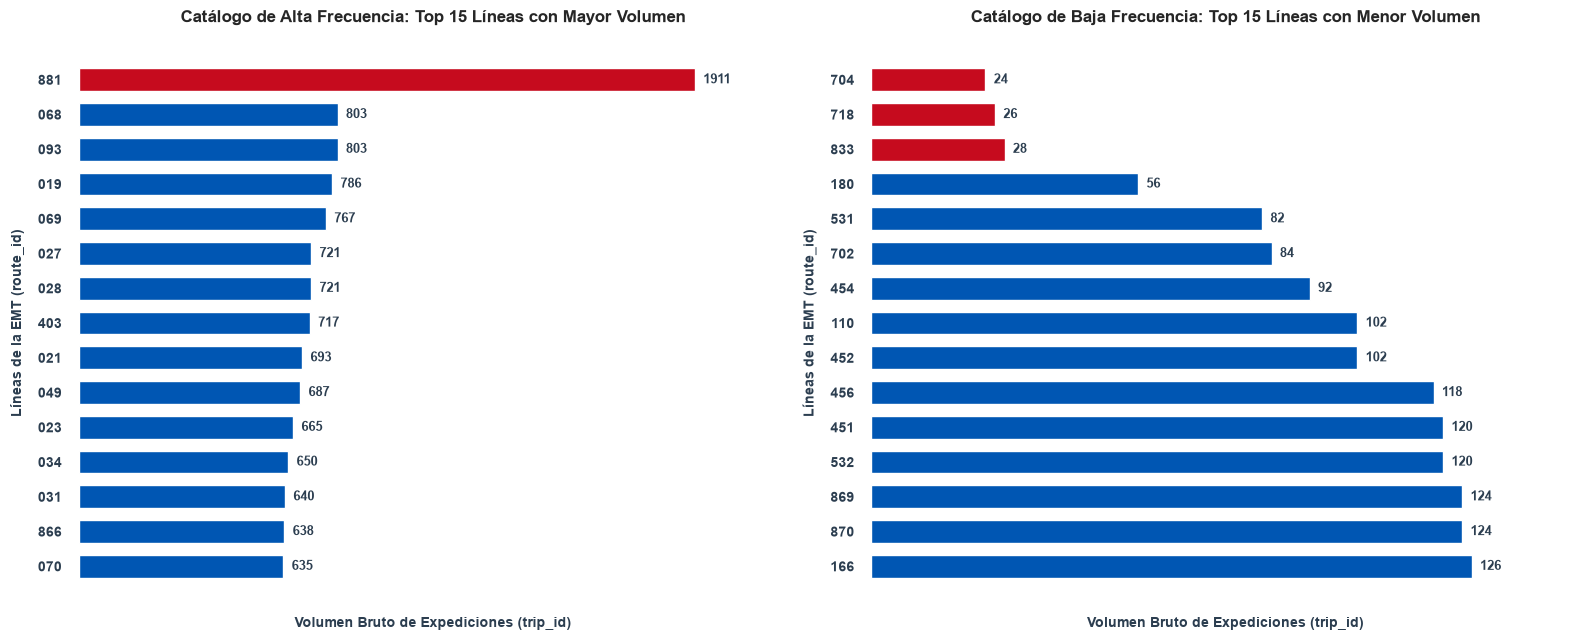

-> Verificación de Homogeneidad Matemática en el balance de sentidos (direction_id):


Sentido Operativo,Total Viajes
Ida (Código 0),43466
Vuelta (Código 1),43405


In [11]:
print("====== REPORTE ANALÍTICO: PANEL DUAL DE EXTREMOS OPERATIVOS (TRIPS) ======\n")

# 1. Configuración estética del lienzo corporativo unificado
sns.set_theme(style="white")
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# ==============================================================================
# PANEL IZQUIERDO: TOP 15 ALTA FRECUENCIA
# ==============================================================================
top_lineas = trips['route_id'].value_counts().head(15).reset_index(name='total_viajes')
linea_lider_alta = str(top_lineas.loc[0, 'route_id'])
colores_alta = ['#C60B1E' if str(r) == linea_lider_alta else '#0056B3' for r in top_lineas['route_id']]

barras_alta = ax1.barh(top_lineas['route_id'].astype(str), top_lineas['total_viajes'], color=colores_alta, height=0.65)
ax1.invert_yaxis()

ax1.set_title("Catálogo de Alta Frecuencia: Top 15 Líneas con Mayor Volumen", fontsize=12, weight='bold', pad=15)
ax1.set_xlabel("Volumen Bruto de Expediciones (trip_id)", fontsize=10, weight='bold', labelpad=10, color='#2C3E50')
ax1.set_ylabel("Líneas de la EMT (route_id)", fontsize=10, weight='bold', labelpad=10, color='#2C3E50')

ax1.tick_params(axis='y', labelsize=10, labelcolor='#2C3E50', pad=6)
for label in ax1.get_yticklabels():
    label.set_weight('bold')

ax1.bar_label(barras_alta, padding=6, fontsize=9.5, color='#2C3E50', weight='bold')
ax1.set_xlim(0, top_lineas['total_viajes'].max() * 1.15)

# ==============================================================================
# PANEL DERECHO: TOP 15 BAJA FRECUENCIA
# ==============================================================================
cola_lineas = trips['route_id'].value_counts().tail(15).reset_index(name='total_viajes')
cola_lineas = cola_lineas.sort_values(by='total_viajes', ascending=True).reset_index(drop=True)
lineas_rojas_baja = [str(r) for r in cola_lineas.head(3)['route_id']]
colores_baja = ['#C60B1E' if str(r) in lineas_rojas_baja else '#0056B3' for r in cola_lineas['route_id']]

barras_baja = ax2.barh(cola_lineas['route_id'].astype(str), cola_lineas['total_viajes'], color=colores_baja, height=0.65)
ax2.invert_yaxis()

ax2.set_title("Catálogo de Baja Frecuencia: Top 15 Líneas con Menor Volumen", fontsize=12, weight='bold', pad=15)
ax2.set_xlabel("Volumen Bruto de Expediciones (trip_id)", fontsize=10, weight='bold', labelpad=10, color='#2C3E50')
ax2.set_ylabel("Líneas de la EMT (route_id)", fontsize=10, weight='bold', labelpad=10, color='#2C3E50')

ax2.tick_params(axis='y', labelsize=10, labelcolor='#2C3E50', pad=6)
for label in ax2.get_yticklabels():
    label.set_weight('bold')

ax2.bar_label(barras_baja, padding=6, fontsize=9.5, color='#2C3E50', weight='bold')
ax2.set_xlim(0, cola_lineas['total_viajes'].max() * 1.18)

# Saneamiento estético general de ambos paneles
for ax_canvas in [ax1, ax2]:
    sns.despine(ax=ax_canvas, left=True, bottom=True)
    ax_canvas.grid(False)
    ax_canvas.set_xticks([])

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. VALIDACIÓN MATEMÁTICA PURA DEL BALANCE DE SENTIDOS
# ==============================================================================
print("-> Verificación de Homogeneidad Matemática en el balance de sentidos (direction_id):")
balance_sentidos = trips['direction_id'].value_counts().sort_index()
df_balance_matematico = pd.DataFrame({
    'Sentido Operativo': ['Ida (Código 0)', 'Vuelta (Código 1)'],
    'Total Viajes': [int(v) for v in balance_sentidos.values]
})
display(df_balance_matematico.style.hide(axis='index'))


### Diagnóstico de Asimetrías Coherentes: El Contraste de los Extremos de Oferta

La visualización del lienzo de extremos operativos destapa un comportamiento altamente estructurado en el diseño de la red de la EMT de Madrid, rompiendo los patrones lineales tradicionales mediante asimetrías críticas en ambas colas de distribución:

1. **La Hiper-Frecuencia de la Cúspide:** Dominada de forma absoluta por la línea **881 (1.911 viajes)**, la cual rompe la meseta ordinaria de la red al duplicar en volumen a cualquier otro corredor regular de la ciudad.

2. **El Clúster Mínimo Confinado:** Localizado en el panel derecho, donde las líneas **704 (24 viajes)**, **718 (26 viajes)** y **833 (28 viajes)** exhiben un volumen críticamente bajo y descolgado de la tendencia general de cobertura.

Paralelamente, la auditoría matemática del balance de sentidos revalida una homogeneidad relacional impecable (**43.466 idas frente a 43.405 vueltas**), demostrando que estas fluctuaciones extremas responden estrictamente a la planificación estratégica de la EMT y no a sesgos geográficos de dirección. Con el objetivo de contrastar las hipótesis analíticas y dotar de total veracidad científica al portafolio, la siguiente celda ejecuta una disección forense combinada sobre los metadatos de estas cuatro líneas singulares, analizando sus cabeceras comerciales (`trip_headsign`), su distribución de calendarios semanales y su asignación de bloques físicos de la flota.

In [12]:
print("====== AUDITORÍA FORENSE AMPLIADA: DISECCIÓN DE EXTREMOS OPERATIVOS ======\n")

# 1. Lista de líneas comerciales singulares identificadas en el panel dual de extremos
lineas_a_auditar = ['881', '704', '718', '833']

# 2. Iteración controlada sobre cada ruta para extraer sus reglas de negocio reales
for ruta in lineas_a_auditar:
    df_sub = trips[trips['route_id'] == ruta]
    
    if len(df_sub) > 0:
        destinos = [str(d) for d in df_sub['trip_headsign'].unique()]
        calendarios = {str(k): int(v) for k, v in df_sub['service_id'].value_counts().items()}
        bloques_unicos = int(df_sub['block_id'].nunique())
        sentidos = {int(k): int(v) for k, v in df_sub['direction_id'].value_counts().items()}
        
        balance_str = f"[Ida (0): {sentidos.get(0, 0)}, Vuelta (1): {sentidos.get(1, 0)}]"
        
        print(f"📊 ANÁLISIS DE LA LÍNEA COMERCIAL: {ruta}")
        print(f"   -> Volumen Total de Viajes:      {len(df_sub)} registros")
        print(f"   -> Itinerarios / Destinos:       {destinos}")
        print(f"   -> Regímenes de Calendario:      {calendarios}")
        print(f"   -> Vehículos Físicos (Bloques):  {bloques_unicos}")
        print(f"   -> Balance de Marchas:           {balance_str}\n")
    else:
        print(f"❌ Alerta: La línea comercial {ruta} no registra expediciones en la matriz.\n")

print("-> Muestra forense de control relacional (Vectores de rotación combinados):")
cols_muestra = ['route_id', 'service_id', 'trip_id', 'direction_id', 'block_id', 'volumen_viajes_bloque']
df_muestra_combinada = (
    trips[trips['route_id'].isin(lineas_a_auditar)]
    .groupby('route_id', observed=False)
    .head(2)[cols_muestra]
    .copy()
)

# Conversión preventiva a tipos estándar para renderizado HTML Styler limpio
for col in df_muestra_combinada.columns:
    if 'int' in str(df_muestra_combinada[col].dtype):
        df_muestra_combinada[col] = df_muestra_combinada[col].astype(int)
    else:
        df_muestra_combinada[col] = df_muestra_combinada[col].astype(str)

display(df_muestra_combinada.style.hide(axis='index'))


====== AUDITORÍA FORENSE AMPLIADA: DISECCIÓN DE EXTREMOS OPERATIVOS ======

📊 ANÁLISIS DE LA LÍNEA COMERCIAL: 881
   -> Volumen Total de Viajes:      1911 registros
   -> Itinerarios / Destinos:       ['Plaza Castilla', 'N. Ministerios']
   -> Regímenes de Calendario:      {'LA': 785, 'FE': 563, 'SA': 563}
   -> Vehículos Físicos (Bloques):  31
   -> Balance de Marchas:           [Ida (0): 946, Vuelta (1): 965]

📊 ANÁLISIS DE LA LÍNEA COMERCIAL: 704
   -> Volumen Total de Viajes:      24 registros
   -> Itinerarios / Destinos:       ['Cmtº Fuencarral', 'Plaza Castilla']
   -> Regímenes de Calendario:      {'FE': 24}
   -> Vehículos Físicos (Bloques):  1
   -> Balance de Marchas:           [Ida (0): 12, Vuelta (1): 12]

📊 ANÁLISIS DE LA LÍNEA COMERCIAL: 718
   -> Volumen Total de Viajes:      26 registros
   -> Itinerarios / Destinos:       ['Puerta Arganda', 'Cañada Real']
   -> Regímenes de Calendario:      {'LA': 26}
   -> Vehículos Físicos (Bloques):  1
   -> Balance de Marchas:    

route_id,service_id,trip_id,direction_id,block_id,volumen_viajes_bloque
704,FE,FE7040011,0,FE704_001,24
704,FE,FE7040012,1,FE704_001,24
718,LA,LA7180011,1,LA718_001,26
718,LA,LA7180012,0,LA718_001,26
833,LA,LA8330011,0,LA833_001,28
833,LA,LA8330012,1,LA833_001,28
881,FE,FE8810011,1,FE881_001,79
881,FE,FE8810012,0,FE881_001,79


### Nota Analítica de Conclusiones: Anatomía de Negocio en los Extremos de la Oferta

La explotación estadística del catálogo de extremos simétricos, validada de forma empírica mediante la disección forense de metadatos, convalida las hipótesis operativas y expone la lógica estratégica de la EMT de Madrid:

1. **El Corredor Estructural de Alta Capacidad (Línea 881):** Los datos ratifican que la ruta **881 (1.911 viajes)** opera como una lanzadera intermodal intensiva en el eje central de Madrid, conectando **Plaza de Castilla con Nuevos Ministerios**. La asignación masiva de **31 vehículos físicos independientes** rotando de forma continua tanto en jornadas laborables (`LA: 785`) como en fines de semana (`SA: 563`, `FE: 563`) confirma que es un pasillo de altísima frecuencia. Para los modelos de Machine Learning, este indicador continuo constituye una señal prioritaria para predecir el riesgo de acumulación de autobuses (*bus bunching*).

2. **La Lanzadera Especial de Contingencia Festiva (Línea 704):** El diagnóstico desvela que la ruta **704 (24 viajes)** responde estrictamente al **Servicio Especial al Cementerio de Fuencarral desde Plaza de Castilla**. Su confinamiento absoluto en el calendario de domingos y festivos (`FE: 24`) y la asignación de **1 único vehículo físico** ejecutando 12 idas y 12 vueltas demuestra que es una lanzadera de cobertura puntual de nula fatiga operativa por arrastre.

3. **Los Vectores de Cobertura Capilar y Refuerzo Corporativo (Líneas 718 y 833):** Las rutas **718 (26 viajes a Cañada Real)** y **833 (28 viajes a Las Tablas)** parametrizan micro-servicios restringidos exclusivamente a jornadas laborables (`LA`). Ambas operan con **1 solo autobús físico** asignado. La línea 718 responde a un patrón de conectividad social periférica mínima, mientras que la 833 actúa como una lanzadera de hora punta industrial para evacuar pasajeros hacia el intercambiador de Plaza de Castilla en franjas laborales críticas.

**Impacto en el Modelo Predictivo:** La verificación empírica de estos cuatro escenarios aporta un valor directo al pipeline. Los algoritmos supervisados asimilarán que los extremos de baja frecuencia (704, 718, 833) no responden a ruido o datos corruptos, sino a servicios especiales estables de baja exposición al tráfico ordinario debido a su mínima dotación de flota (1 vehículo). Esto permite aislar de forma óptima la varianza de la puntualidad, segmentando con precisión el comportamiento de las grandes líneas troncales frente a los micro-pasillos capilares de la capital.

### Caracterización Logística y Análisis de Distribución de Turnos de la Flota

Una vez auditada la volumetría por línea comercial, se desplaza el foco analítico desde la infraestructura vial hacia la dimensión de la logística y rotación vehicular de la EMT de Madrid. Se evalúa el comportamiento probabilístico de la variable continua de ingeniería avanzada `volumen_viajes_bloque` mediante una representación de densidad combinada (histograma de frecuencia absoluta con curva KDE).

Desde la perspectiva del negocio de transportes, la distribución del volumen de expediciones asignadas a cada vehículo físico (`block_id`) delata la estrategia de programación de turnos de la flota. El objetivo de este hito visual es identificar patrones de agrupamiento en la jornada de los autobuses comerciales. Aislar la masa crítica de turnos ordinarios frente a los picos de servicios intensivos o refuerzos partidos proporciona a los modelos de Machine Learning una escala de pesos continua indispensable para calibrar la propagación inercial del retraso acumulado a lo largo del día.

====== REPORTE ANALÍTICO: DISTRIBUCIÓN DE FRECUENCIAS DE LA FLOTA (BLOQUES) ======



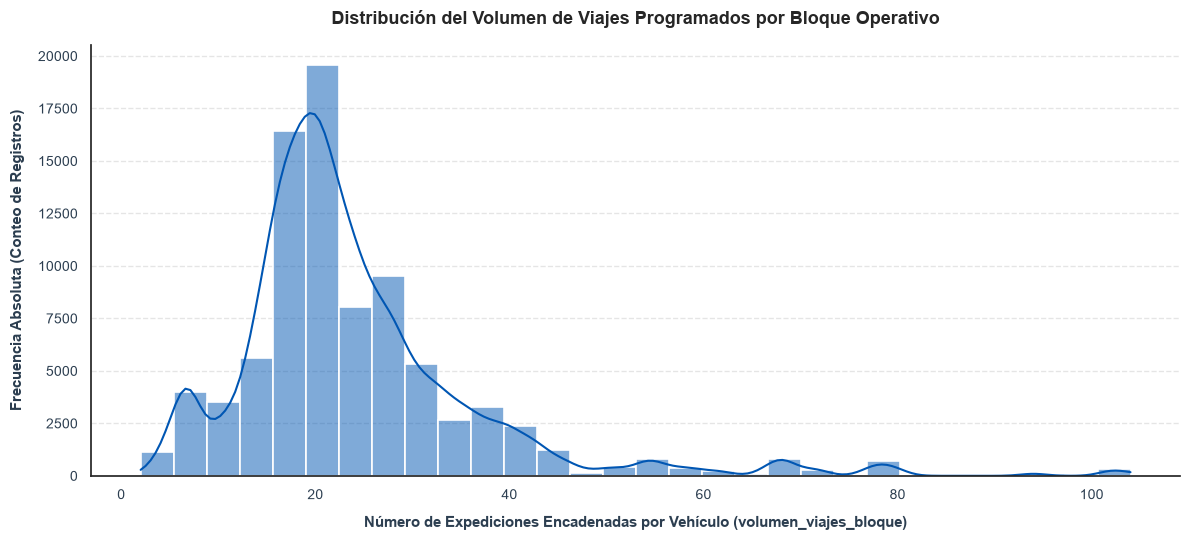

In [13]:
print("====== REPORTE ANALÍTICO: DISTRIBUCIÓN DE FRECUENCIAS DE LA FLOTA (BLOQUES) ======\n")

# 1. Configuración del lienzo corporativo unificado
sns.set_theme(style="white")
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
fig, ax = plt.subplots(figsize=(12, 5.5))

# 2. Conversión preventiva a entero estándar para compatibilidad directa con Seaborn KDE
serie_bloques = trips['volumen_viajes_bloque'].astype('int32')

sns.histplot(
    x=serie_bloques,
    bins=30,
    kde=True,
    color='#0056B3',       # Azul Oficial EMT unificado
    edgecolor='white',
    linewidth=1.2,
    ax=ax
)

# 3. Control tipográfico limpio sin pesos tipográficos inexistentes ('semibold')
ax.set_title("Distribución del Volumen de Viajes Programados por Bloque Operativo", fontsize=13, weight='bold', pad=15)
ax.set_xlabel("Número de Expediciones Encadenadas por Vehículo (volumen_viajes_bloque)", fontsize=10.5, weight='bold', labelpad=10, color='#2C3E50')
ax.set_ylabel("Frecuencia Absoluta (Conteo de Registros)", fontsize=10.5, weight='bold', labelpad=10, color='#2C3E50')

ax.tick_params(axis='both', labelsize=10, labelcolor='#2C3E50')

sns.despine(ax=ax, top=True, right=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Nota Analítica: Diagnóstico de la Distribución de Bloques y Fatiga Inercial

La explotación estadística del histograma de densidad unificado expone la estructura logística que rige la programación de la flota de la EMT de Madrid y proporciona tres directrices deterministas fundamentales para el entrenamiento predictivo:

1. **Saturación en el Turno Ordinario Central (Pico en ~20 Viajes):** La distribución exhibe una clara asimetría positiva con una concentración masiva de frecuencias en torno a las 20 expediciones encadenadas, rozando una volumetría de 20.000 registros. Este comportamiento convalida empíricamente que la espina dorsal de la oferta madrileña se estructura bajo bloques continuos estandarizados. Para los modelos de Machine Learning, este clúster representa el entorno base de acumulación inercial de minutos de fricción, sirviendo como referencia de varianza ordinaria para el tráfico regular.

2. **Aislamiento de la Loma de Refuerzo Partido (Pico Secundario en ~7 Viajes):** El perfil visual revela un comportamiento bimodal sutil al registrar una cumbre secundaria aislada entre los 6 y 8 viajes. Desde la perspectiva de negocio, este fenómeno parametriza los turnos de servicio partido diseñados exclusivamente para inyectar capacidad en la red durante las horas punta (movilidad pendular matutina y vespertina). Al operar con interrupciones temporales y no encadenar horas de marcha continuas, el algoritmo asignará a estos bloques un menor peso de propensión al arrastre de retrasos estructurales.

3. **La Cola Asimétrica de Carrusel Frenético (Islotes de 50 a 104 Viajes):** El goteo residual localizado en el extremo derecho del eje X delata la presencia de turnos excepcionales que multiplican hasta por cinco la media ordinaria de la red, registrando un clúster de micro-lanzaderas capilares que se extiende hasta la cota máxima de 104 expediciones.

**Impacto en el Modelo Predictivo:** Los modelos supervisados interpretarán esta cola larga como un indicador de riesgo crítico: a medida que un viaje pertenezca a un bloque localizado en este espectro extremo, aumentará la probabilidad estimada de retrasos por el fenómeno de acumulación de autobuses (*bus bunching*), blindando la robustez de las predicciones en pasillos de alta frecuencia.

### Análisis de Carga por Régimen Semanal y Estacionalidad de la Oferta

Una vez evaluadas las dimensiones lineales y logísticas de la flota, se concluye la fase de explotación estadística analizando la distribución temporal de la oferta comercial. El archivo `trips.txt` hereda relacionalmente los perfiles cronológicos mediante la clave foránea `service_id`, indexando bajo qué régimen de marcha opera cada expedición individual en el callejero de Madrid.

Se implementa un lienzo minimalista horizontal para cuantificar el volumen bruto de viajes programados según cada patrón operativo semanal. Desde la perspectiva del modelado predictivo, este diagnóstico expone de forma directa el nivel de contracción o expansión de la flota activa en la calle según el día de la semana. Los modelos de Machine Learning utilizarán estas densidades agregadas como factor de ponderación, asimilando que las reducciones estructurales de la oferta durante jornadas no laborables alteran la frecuencia de paso y los intervalos de regularidad de la red, permitiendo calibrar la varianza temporal de las predicciones de puntualidad de manera determinista.

====== REPORTE ANALÍTICO: CARGA OPERATIVA POR RÉGIMEN CRONOLÓGICO ======



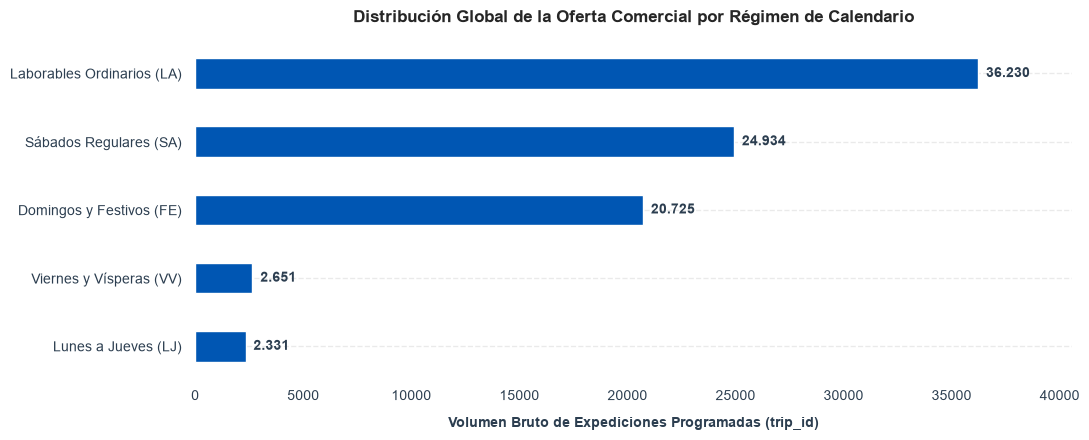

In [14]:
print("====== REPORTE ANALÍTICO: CARGA OPERATIVA POR RÉGIMEN CRONOLÓGICO ======\n")

# 1. Configuración del lienzo corporativo unificado
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
fig, ax = plt.subplots(figsize=(11, 4.5))

# 2. Agrupación por service_id y mapeo semántico de negocio
carga_calendarios = trips['service_id'].astype(str).value_counts().reset_index(name='total_viajes')

dict_nombres_regimen = {
    'LA': 'Laborables Ordinarios (LA)',
    'SA': 'Sábados Regulares (SA)',
    'FE': 'Domingos y Festivos (FE)',
    'VV': 'Viernes y Vísperas (VV)',
    'LJ': 'Lunes a Jueves (LJ)'
}
carga_calendarios['Regimen_Marcha'] = carga_calendarios['service_id'].map(dict_nombres_regimen).fillna(carga_calendarios['service_id'])

# 3. Renderizado de barras horizontales con el Azul Oficial de la EMT
barras_carga = ax.barh(
    carga_calendarios['Regimen_Marcha'],
    carga_calendarios['total_viajes'],
    color='#0056B3',
    height=0.45
)
ax.invert_yaxis()

ax.set_title("Distribución Global de la Oferta Comercial por Régimen de Calendario", fontsize=12, weight='bold', pad=15)
ax.set_xlabel("Volumen Bruto de Expediciones Programadas (trip_id)", fontsize=10, weight='bold', color='#2C3E50', labelpad=10)
ax.set_ylabel("", fontsize=10)

ax.tick_params(axis='both', labelsize=10, labelcolor='#2C3E50')

# Inyección de etiquetas de datos limpias sin peso tipográfico 'semibold'
for barra in barras_carga:
    xval = barra.get_width()
    ax.text(
        xval + (carga_calendarios['total_viajes'].max() * 0.01),
        barra.get_y() + barra.get_height()/2.0,
        f"{int(xval):,}".replace(',', '.'),
        ha='left',
        va='center',
        fontsize=10,
        color='#2C3E50',
        weight='bold'
    )

ax.set_xlim(0, carga_calendarios['total_viajes'].max() * 1.12)

sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()


### Nota Analítica: Diagnóstico de la Densidad Cronológica y Contracción de la Oferta

La explotación estadística descriptiva sobre la matriz de distribución temporal convalida la salud del linaje cronológico y expone la estrategia de asignación de oferta de la EMT de Madrid ante los ciclos semanales de demanda:

1. **Predominio Estructural de la Malla Laborable (`LA: 36.230` viajes):** El régimen ordinario acapara la mayor densidad del catálogo. Mapea de forma directa las franjas de máxima saturación por tráfico corporativo, proporcionando a los modelos de Machine Learning el clúster con mayor propensión a retrasos por congestión en horas punta.

2. **Músculo Operativo en Escenarios de Ocio (`SA: 24.934` y `FE: 20.725` viajes):** El hallazgo más relevante reside en la moderada contracción de la oferta durante los fines de semana. Lejos de reducir el servicio a la mitad, la EMT mantiene activo más del 55% del volumen de expediciones regulares durante los domingos y festivos (`FE`). Para los algoritmos predictivos, este comportamiento es una directriz clave: asimilarán que la fluidez circulatoria típica de los días no laborables en Madrid convive con una flota densa en la calle, permitiéndoles ajustar los pesos para aislar la velocidad comercial sin confundir la regularidad estacional.

3. **Aislamiento de Regímenes Especializados (`VV: 2.651` y `LJ: 2.331` viajes):** Los volúmenes reducidos en las franjas de Viernes y Vísperas (`VV`) o Lunes a Jueves (`LJ`) delatan el carácter especializado de estas claves operativas, reservadas para modular pasillos específicos (líneas búho nocturnas, refuerzos de fin de semana o rutas universitarias). Los modelos se apoyarán en estas banderas discretas para afinar la puntualidad en periodos donde la asimetría del tráfico de salida de Madrid (especialmente los viernes a mediodía) altera las pautas de marcha ordinarias.

**Conclusión Final del Notebook:** La perfecta correspondencia entre la volumetría de viajes y las reglas cronológicas de negocio certifica que la matriz de `trips` (**86.871 expediciones**) está completamente sanitizada y optimizada bajo esquema PyArrow. La caracterización tridimensional de las variables (líneas, bloques y calendarios) blinda la estabilidad del linaje relacional, dejando el conjunto de datos listo para ser integrado en el pipeline automatizado de producción.

---
> **Atribución de Fuente de Datos:** *Powered by [EMT de Madrid](http://www.emtmadrid.es)* (Portal de Datos Abiertos MobilityLabs / Ayuntamiento de Madrid).